<a href="https://colab.research.google.com/github/houdafe83-lab/micro-m2-2026/blob/main/data_micro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/micro m2.xlsx'

try:
    # Lire le fichier Excel pour obtenir les noms des feuilles
    excel_file = pd.ExcelFile(file_path)
    print("Feuilles disponibles :", excel_file.sheet_names)

    # Charger la première feuille par défaut
    df = excel_file.parse(excel_file.sheet_names[0])
    print(f"\nDimensions de la feuille '{excel_file.sheet_names[0]}' : {df.shape[0]} lignes, {df.shape[1]} colonnes")

    # Afficher un aperçu des données
    display(df.head())
except Exception as e:
    print(f"Erreur lors de la lecture du fichier : {e}")

Feuilles disponibles : ['Sheet1']

Dimensions de la feuille 'Sheet1' : 202 lignes, 26 colonnes


,Title & authors,Unnamed: 1,Year,Journal,Country Studied,Country of first author institution,Scale,Scale of study,Rationale,Ecosystem service studied,...,Machine learning technique used,Program/Software,Unnamed: 18,Mention Big Data?,Big Data Used,Mention Climate change,Implication for climate change,Explicitly Study Climate Change?,How is Climate Change Integrated,ES Supply or Demand?
0,Balbi et al. ﻿Human dependence on natural reso...,2019,2019.0,Environmental Research Letters,South Africa,Spain,Local,Local,Modeling local dependence on natural resources...,Fresh water supply,...,Bayesian Network,WEKA,no,no,NaN,no,NaN,no,NaN,Demand
1,NaN,2019,NaN,NaN,NaN,NaN,Local,NaN,NaN,Food provision,...,NaN,NaN,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2019,NaN,NaN,NaN,NaN,Local,NaN,NaN,Raw materials,...,NaN,NaN,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,2019,NaN,NaN,NaN,NaN,Local,NaN,NaN,Raw materials,...,NaN,NaN,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,2019,NaN,NaN,NaN,NaN,Local,NaN,NaN,NaN,...,NaN,NaN,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import pandas as pd
import numpy as np

# Exploration des colonnes pour la modélisation
info_df = pd.DataFrame({
    'Type': df.dtypes,
    'Valeurs non nulles': df.count(),
    'Valeurs manquantes (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Valeurs uniques': df.nunique()
})

print("--- Analyse globale du jeu de données ---")
display(info_df)

# Suggestions automatiques de variables cibles (Y) et explicatives (X)
candidats_y_classification = info_df[(info_df['Type'] == 'object') & (info_df['Valeurs uniques'].between(2, 10))].index.tolist()
candidats_y_regression = info_df[(info_df['Type'].isin(['int64', 'float64'])) & (info_df['Valeurs uniques'] > 10)].index.tolist()
candidats_x = info_df[info_df['Valeurs manquantes (%)'] < 50].index.tolist()

print("\n--- Suggestions pour la modélisation ---")
print(f"Cibles potentielles (Y) pour de la Classification (variables catégorielles avec peu de classes) :\n{candidats_y_classification}\n")
print(f"Cibles potentielles (Y) pour de la Régression (variables numériques continues) :\n{candidats_y_regression}\n")
print(f"Variables explicatives potentielles (X) (moins de 50% de valeurs manquantes) :\n{candidats_x}")

--- Analyse globale du jeu de données ---


,Type,Valeurs non nulles,Valeurs manquantes (%),Valeurs uniques
Title & authors,object,53,73.76,53
Unnamed: 1,int64,202,0.00,7
Year,float64,53,73.76,7
Journal,object,53,73.76,33
Country Studied,object,54,73.27,25
Country of first author institution,object,53,73.76,19
Scale,object,202,0.00,4
Scale of study,object,54,73.27,4
Rationale,object,53,73.76,53
Ecosystem service studied,object,106,47.52,16



--- Suggestions pour la modélisation ---
Cibles potentielles (Y) pour de la Classification (variables catégorielles avec peu de classes) :
['Scale', 'Scale of study', 'Ecosystem Services Class', 'Indicator Class', 'Supervised/Unsupervised or None', 'Unnamed: 18', 'Mention Big Data?', 'Mention Climate change ', 'Explicitly Study Climate Change?', 'How is Climate Change Integrated', 'ES Supply or Demand?']

Cibles potentielles (Y) pour de la Régression (variables numériques continues) :
[]

Variables explicatives potentielles (X) (moins de 50% de valeurs manquantes) :
['Unnamed: 1', 'Scale', 'Ecosystem service studied', 'Ecosystem Services Class', 'Indicator Used', 'Indicator Class', 'Data Source', 'Unnamed: 18']


In [ ]:
# Définition des variables explicatives (X) et de la variable cible (Y) choisie pour l'analyse
# Vous pouvez modifier ces listes selon vos besoins réels de modélisation
features_x = ['Scale', 'Ecosystem service studied', 'Ecosystem Services Class', 'Indicator Class', 'Data Source']
target_y = 'Explicitly Study Climate Change?'  # Exemple de variable cible catégorielle

def expliquer_nature_variables(df, x_cols, y_col):
    print("=== EXPLORATION DE LA NATURE DES VARIABLES ===\n")

    # Analyse de la cible Y
    print(f"--- VARIABLE CIBLE (Y) : {y_col} ---")
    print(f"Type de données : {df[y_col].dtype}")
    print(f"Valeurs manquantes : {df[y_col].isnull().sum()} ({df[y_col].isnull().mean()*100:.2f}%)")
    print("Distribution des classes (Top 5) :")
    print(df[y_col].value_counts(dropna=False).head())
    print("\n" + "="*50 + "\n")

    # Analyse des variables explicatives X
    print("--- VARIABLES EXPLICATIVES (X) ---")
    for col in x_cols:
        if col not in df.columns:
            continue
        print(f"\n> Variable : {col}")
        print(f"  Type : {df[col].dtype}")
        print(f"  Valeurs manquantes : {df[col].isnull().sum()} ({df[col].isnull().mean()*100:.2f}%)")
        print(f"  Nombre de valeurs uniques : {df[col].nunique()}")

        # Nature : Numérique ou Catégorielle
        if pd.api.types.is_numeric_dtype(df[col]):
            print("  Nature : Numérique (Quantitative)")
            print(f"  Moyenne : {df[col].mean():.2f} | Min : {df[col].min()} | Max : {df[col].max()}")
        else:
            print("  Nature : Catégorielle (Qualitative)")
            print("  Exemples de catégories :", df[col].dropna().unique()[:5])

expliquer_nature_variables(df, features_x, target_y)

=== EXPLORATION DE LA NATURE DES VARIABLES ===

--- VARIABLE CIBLE (Y) : Explicitly Study Climate Change? ---
Type de données : object
Valeurs manquantes : 148 (73.27%)
Distribution des classes (Top 5) :
Explicitly Study Climate Change?
NaN    148
no      50
yes      4
Name: count, dtype: int64


--- VARIABLES EXPLICATIVES (X) ---

> Variable : Scale
  Type : object
  Valeurs manquantes : 0 (0.00%)
  Nombre de valeurs uniques : 4
  Nature : Catégorielle (Qualitative)
  Exemples de catégories : ['Local' 'National' 'Global' 'Regional']

> Variable : Ecosystem service studied
  Type : object
  Valeurs manquantes : 96 (47.52%)
  Nombre de valeurs uniques : 16
  Nature : Catégorielle (Qualitative)
  Exemples de catégories : ['Fresh water supply' 'Food provision' 'Raw materials'
 'Aesthetic appreciation' 'Recreation']

> Variable : Ecosystem Services Class
  Type : object
  Valeurs manquantes : 95 (47.03%)
  Nombre de valeurs uniques : 6
  Nature : Catégorielle (Qualitative)
  Exemples de ca

/tmp/ipykernel_1157/2035819393.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[features_x[i] for i in indices], palette='viridis')


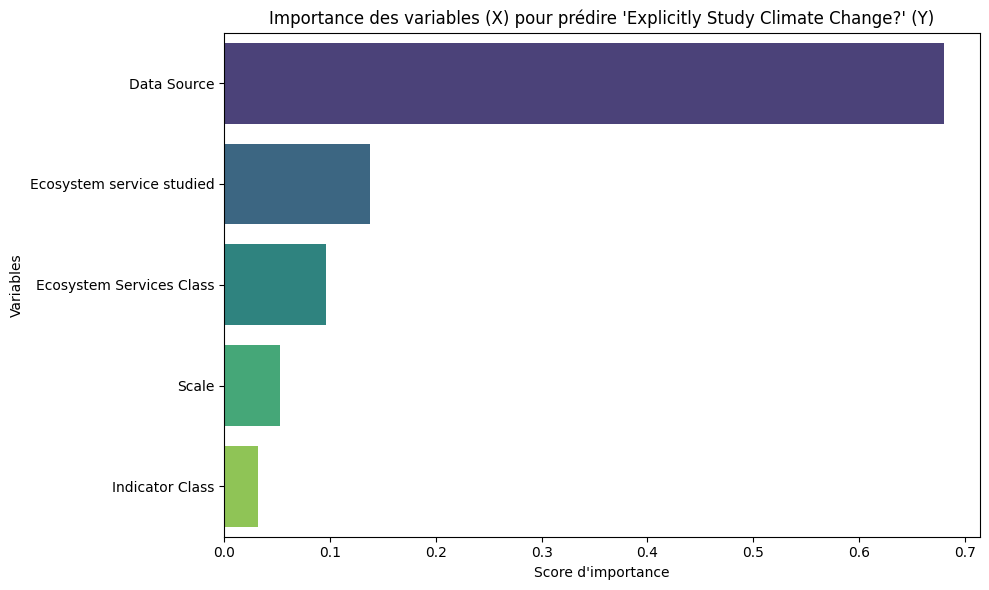

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Préparation des données pour l'explication par modèle
# On filtre les lignes où Y n'est pas nul
df_clean = df.dropna(subset=[target_y]).copy()

# Remplissage des valeurs manquantes dans X pour l'entraînement
for col in features_x:
    df_clean[col] = df_clean[col].fillna("Inconnu")

# Encodage des variables catégorielles
label_encoders = {}
df_encoded = pd.DataFrame()

for col in features_x:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col].astype(str))
    label_encoders[col] = le

le_y = LabelEncoder()
y = le_y.fit_transform(df_clean[target_y].astype(str))
X = df_encoded[features_x]

# Entraînement d'un modèle pour évaluer l'importance des variables
model = RandomForestClassifier(random_state=42)
model.fit(X, y)

# Calcul et affichage de l'importance des variables
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

# Visualisation graphique
plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=[features_x[i] for i in indices], palette='viridis')
plt.title(f"Importance des variables (X) pour prédire '{target_y}' (Y)")
plt.xlabel("Score d'importance")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()